In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("solar_system.csv")
print(df.shape)
# 20 rows, 11 columns 

(20, 11)


In [4]:
df.head()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3


In [5]:
df.tail()

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
15,Mean Temperature (C),167,464,15,-20,-65,-110,-140,-195,-200,-225
16,Surface Pressure (bars),0,92,1,0,0.01,Unknown,Unknown,Unknown,Unknown,0.00001
17,Number of Moons,0,0,1,0,2,95,274,28,16,5
18,Ring System?,No,No,No,No,No,Yes,Yes,Yes,Yes,No
19,Global Magnetic Field?,Yes,No,Yes,No,No,Yes,Yes,Yes,Yes,Unknown


In [6]:
print("\nColumn names:", df.columns.tolist())


Column names: ['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto']


In [11]:
df = df.set_index("Attribute")
print("Row names:", df.index.tolist())

Row names: ['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)', 'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)', 'Length of Day (hours)', 'Distance from Sun (10^6 km)', 'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)', 'Orbital Velocity (km/s)', 'Orbital Inclination (deg)', 'Orbital Eccentricity', 'Obliquity to Orbit (deg)', 'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons', 'Ring System?', 'Global Magnetic Field?']


In [13]:
perihelion = df.iloc[8, 1:].astype(float)
aphelion = df.iloc[9, 1:].astype(float)
orbital_period = df.iloc[10, 1:].astype(float)

print("Orbital period (days):\n", orbital_period)
print("\nPerihelion (10^6 km):\n", perihelion)
print("\nAphelion (10^6 km):\n", aphelion)

Orbital period (days):
 Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: Orbital Period (days), dtype: float64

Perihelion (10^6 km):
 Venus       107.500
Earth       147.100
Moon          0.363
Mars        206.700
Jupiter     740.600
Saturn     1357.600
Uranus     2732.700
Neptune    4471.100
Pluto      4436.800
Name: Perihelion (10^6 km), dtype: float64

Aphelion (10^6 km):
 Venus       108.900
Earth       152.100
Moon          0.406
Mars        249.300
Jupiter     816.400
Saturn     1506.500
Uranus     3001.400
Neptune    4558.900
Pluto      7375.900
Name: Aphelion (10^6 km), dtype: float64


In [14]:
# Perihelion: The point in an elliptical orbit where a planet or object is closest to the Sun.
# Aphelion: The point in an elliptical orbit where a planet or object is farthest from the Sun.
# Semi-major axis: Half of the longest diameter of an elliptical orbit, representing the average distance between the orbiting body and the Sun.

In [37]:
semi_major_axis = (perihelion + aphelion) / 2

new_row = pd.Series(
    {"Attribute": "Semi-major Axis (10^6 km)", **semi_major_axis.to_dict()}
)
df = pd.concat([df, new_row.to_frame().T], ignore_index=True)

print("New DataFrame shape:", df.shape)
# 22 rows, 11 columns

New DataFrame shape: (23, 11)


Length of semi_major_axis: 9
Length of orbital_period: 9
Length after trimming to match: 9, 9
Length after cleaning - semi_major_axis: 9
Length after cleaning - orbital_period: 9
Best-fit parameter m: 0.198200


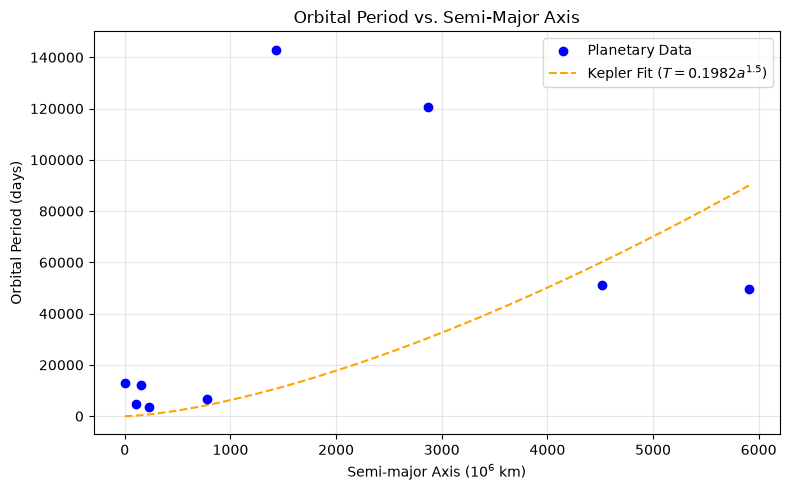

In [39]:
def keplers_third_law(a, m):
    return m * a**1.5

print(f"Length of semi_major_axis: {len(semi_major_axis)}")
print(f"Length of orbital_period: {len(orbital_period)}")

# FIX: Ensure both arrays have the same length first by trimming to the shorter length
min_length = min(len(semi_major_axis), len(orbital_period))
semi_major_axis = semi_major_axis[:min_length]
orbital_period = orbital_period[:min_length]

print(f"Length after trimming to match: {len(semi_major_axis)}, {len(orbital_period)}")

valid_mask = ~(np.isnan(semi_major_axis) | np.isnan(orbital_period))
semi_major_axis_clean = semi_major_axis[valid_mask]
orbital_period_clean = orbital_period[valid_mask]

print(f"Length after cleaning - semi_major_axis: {len(semi_major_axis_clean)}")
print(f"Length after cleaning - orbital_period: {len(orbital_period_clean)}")

# Now use the cleaned arrays for curve fitting
popt, pcov = curve_fit(keplers_third_law, semi_major_axis_clean, orbital_period_clean)
m_fit = popt[0]
print(f"Best-fit parameter m: {m_fit:.6f}")

a_vals = np.linspace(semi_major_axis_clean.min(), semi_major_axis_clean.max(), 200)
t_fit = keplers_third_law(a_vals, m_fit)

plt.figure(figsize=(8, 5))
plt.scatter(
    semi_major_axis_clean,  # Use cleaned data for plotting
    orbital_period_clean,   # Use cleaned data for plotting
    color="blue",
    label="Planetary Data",
    zorder=3,
)
plt.plot(
    a_vals,
    t_fit,
    color="orange",
    linestyle="--",
    label=f"Kepler Fit ($T = {m_fit:.4f} a^{{1.5}}$)",
)

plt.xlabel("Semi-major Axis ($10^6$ km)")
plt.ylabel("Orbital Period (days)")
plt.title("Orbital Period vs. Semi-Major Axis")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

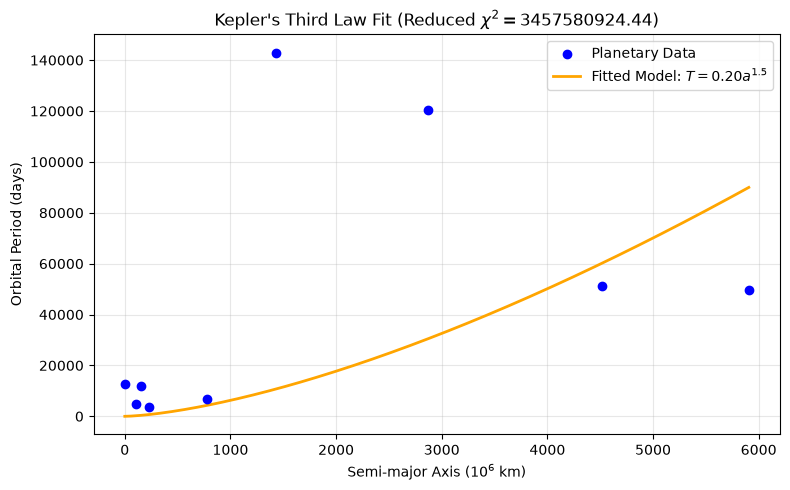

In [38]:
t_predicted = keplers_third_law(semi_major_axis, m_fit)

uncertainty = 1.0  
chi_squared = np.sum(((orbital_period - t_predicted) / uncertainty) ** 2)

degrees_of_freedom = len(orbital_period) - 1  # 1 parameter (m_fit) was fitted
reduced_chi_squared = chi_squared / degrees_of_freedom

a_smooth = np.linspace(semi_major_axis.min(), semi_major_axis.max(), 200)
t_smooth = keplers_third_law(a_smooth, m_fit)

plt.figure(figsize=(8, 5))

plt.scatter(
    semi_major_axis,
    orbital_period,
    color="blue",
    label="Planetary Data",
    zorder=3,
)

plt.plot(
    a_smooth,
    t_smooth,
    color="orange",
    linewidth=2,
    label=f"Fitted Model: $T = {m_fit:.2f} a^{{1.5}}$",
)
plt.title(
    f"Kepler's Third Law Fit (Reduced $\\chi^2 = {reduced_chi_squared:.2f}$)"
)

plt.xlabel("Semi-major Axis ($10^6$ km)")
plt.ylabel("Orbital Period (days)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df.to_csv("kepler.csv", index=False)